
# 02. Data Cleaning — Australian Legal Corpus

## Objective
This notebook cleans the 1,000-document sample of the Open Australian Legal Corpus for the LexiAssist legal research assistant.

### Cleaning Tasks
1. Identify and handle missing values
2. Detect duplicate records
3. Standardize data formats
4. Clean text and metadata
5. Investigate outliers
6. Validate and export the cleaned dataset


##1. Environment Setup and Dataset Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)
print("Loaded:", filename)
print("Shape:", df.shape)

Saving australian_legal_corpus_sample.csv to australian_legal_corpus_sample (2).csv
Loaded: australian_legal_corpus_sample (2).csv
Shape: (1000, 10)


##2. Initial Data Quality Assessment

In [ ]:
print("DATASET INFORMATION")
df.info()
print("\nMISSING VALUES")
display(df.isnull().sum())
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())
print("\nDUPLICATE DOCUMENT IDS")
print(df["version_id"].duplicated().sum())
print("\nDUPLICATE TEXT")
print(df["text"].duplicated().sum())
print("\nDATA TYPES")
display(df.dtypes)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   version_id    1000 non-null   object             
 1   type          1000 non-null   object             
 2   jurisdiction  1000 non-null   object             
 3   source        1000 non-null   object             
 4   mime          1000 non-null   object             
 5   date          893 non-null    datetime64[ns]     
 6   citation      1000 non-null   object             
 7   url           1000 non-null   object             
 8   when_scraped  1000 non-null   datetime64[ns, UTC]
 9   text          1000 non-null   object             
 10  date_missing  1000 non-null   bool               
dtypes: bool(1), datetime64[ns, UTC](1), datetime64[ns](1), object(8)
memory usage: 79.2+ KB

MISSING VALUES


,0
version_id,0
type,0
jurisdiction,0
source,0
mime,0
date,107
citation,0
url,0
when_scraped,0
text,0



DUPLICATE ROWS
0

DUPLICATE DOCUMENT IDS
0

DUPLICATE TEXT
0

DATA TYPES


,0
version_id,object
type,object
jurisdiction,object
source,object
mime,object
date,datetime64[ns]
citation,object
url,object
when_scraped,"datetime64[ns, UTC]"
text,object



### Initial Data Quality Findings

The dataset contains 1,000 legal documents and 10 attributes.

The initial audit identified:
- 107 missing values in the `date` column (10.7%).
- No fully duplicated records.
- No duplicate document identifiers or document text.
- Five repeated citation values requiring further inspection.

The next step is to investigate missing dates and determine an appropriate handling strategy while preserving the integrity of the legal corpus.


##3. Missing Publication Date Investigation

In [ ]:
print("MISSING DATES BY DOCUMENT TYPE")
display(
    df.groupby("type")["date"]
      .apply(lambda x: x.isna().sum())
      .sort_values(ascending=False)
)
print("\nMISSING DATES BY SOURCE")
display(
    df.groupby("source")["date"]
      .apply(lambda x: x.isna().sum())
      .sort_values(ascending=False)
)
print("\nEXAMPLES OF DOCUMENTS WITH MISSING DATES")
display(
    df.loc[df["date"].isna(),
           ["version_id", "type", "source", "citation"]].head(10))


MISSING DATES BY DOCUMENT TYPE


,date
type,
decision,55
bill,35
primary_legislation,17
secondary_legislation,0



MISSING DATES BY SOURCE


,date
source,
high_court_of_australia,55
queensland_legislation,22
nsw_legislation,17
south_australian_legislation,13
nsw_caselaw,0
federal_court_of_australia,0
tasmanian_legislation,0
western_australian_legislation,0



EXAMPLES OF DOCUMENTS WITH MISSING DATES


,version_id,type,source,citation
5,high_court_of_australia:/showbyHandle/1/10179,decision,high_court_of_australia,Richardson v Commercial Banking Co of Sydney L...
9,south_australian_legislation:9e160d450a148f2e/...,bill,south_australian_legislation,Environment Protection (Objects of Act and Boa...
31,south_australian_legislation:eb65c46855aa9890/...,bill,south_australian_legislation,Climate Change and Greenhouse Emissions Reduct...
38,high_court_of_australia:/showbyHandle/1/11271,decision,high_court_of_australia,Laybutt v Amoco Australia Pty Ltd [1974] HCA 49
59,queensland_legislation:bill.first/bill-2020-041,bill,queensland_legislation,Nature Conservation and Other Legislation (Ind...
63,high_court_of_australia:/showbyHandle/1/10726,decision,high_court_of_australia,JB Witts Pty Ltd v Wholesalers (Aust) Pty Ltd ...
67,queensland_legislation:bill.first/bill-2024-008,bill,queensland_legislation,Help to Buy (Commonwealth Powers) Bill 2024 (Qld)
74,nsw_legislation:asmade/act-1890-mrh,primary_legislation,nsw_legislation,Municipalities of Ryde and Hunter's Hill Act o...
81,queensland_legislation:bill.first/bill-2023-045,bill,queensland_legislation,Planning and Other Legislation (Make Developer...
97,queensland_legislation:bill.first/bill-2021-052,bill,queensland_legislation,Animal Care and Protection Amendment Bill 2022...



### Missing Date Investigation

The dataset contains 107 missing publication dates (10.7%).

Missing values are concentrated in specific document categories:
- 55 High Court decisions
- 35 bills
- 17 NSW primary legislation documents

These missing values appear to be associated with particular data sources and document categories rather than being uniformly distributed.

**Handling Strategy:**

Missing publication dates will be preserved as missing values (`NaT`) rather than filled with arbitrary dates.

This avoids introducing inaccurate legal metadata. Documents with missing dates will remain in the dataset because their legal text is still valuable for the retrieval system.


In [ ]:

df["date_missing"] = df["date"].isna()
df["date"] = pd.to_datetime(
    df["date"], errors="coerce"
)
df["when_scraped"] = pd.to_datetime(
    df["when_scraped"],
    errors="coerce",
    utc=True
)
print("Missing publication dates:", df["date"].isna().sum())
print("Dataset shape:", df.shape)
display(df[["date", "when_scraped", "date_missing"]].head())


Missing publication dates: 107
Dataset shape: (1000, 11)


,date,when_scraped,date_missing
0,2000-08-02,2024-09-13 12:47:55.638633+00:00,False
1,2018-04-27,2024-09-13 13:44:14.576816+00:00,False
2,2017-04-27,2024-09-13 13:29:05.309922+00:00,False
3,2020-12-02,2024-09-13 13:08:39.283882+00:00,False
4,2000-12-27,2024-09-13 13:08:12.380116+00:00,False


##4. Duplicate Detection and Validation

In [ ]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate document IDs:", df["version_id"].duplicated().sum())
print("Duplicate URLs:", df["url"].duplicated().sum())
print("Duplicate texts:", df["text"].duplicated().sum())
print("Repeated citation entries:", df["citation"].duplicated().sum())
repeated_citations = df[
    df["citation"].duplicated(keep=False)
].sort_values("citation")

print("\nDocuments with repeated citations:")
display(
    repeated_citations[
        ["version_id", "citation", "date", "source", "url"]
    ]
)


Fully duplicated rows: 0
Duplicate document IDs: 0
Duplicate URLs: 0
Duplicate texts: 0
Repeated citation entries: 5

Documents with repeated citations:


,version_id,citation,date,source,url
0,tasmanian_legislation:2000-08-02/sr-2000-118,Proclamation under the National Parks and Wild...,2000-08-02,tasmanian_legislation,https://www.legislation.tas.gov.au/view/whole/...
4,tasmanian_legislation:2000-12-27/sr-2000-244,Proclamation under the National Parks and Wild...,2000-12-27,tasmanian_legislation,https://www.legislation.tas.gov.au/view/whole/...
8,tasmanian_legislation:2000-08-02/sr-2000-109,Proclamation under the National Parks and Wild...,2000-08-02,tasmanian_legislation,https://www.legislation.tas.gov.au/view/whole/...
101,tasmanian_legislation:2012-12-26/sr-2012-136,Proclamation under the Nature Conservation Act...,2012-12-26,tasmanian_legislation,https://www.legislation.tas.gov.au/view/whole/...
495,tasmanian_legislation:2016-11-16/sr-2016-094,Proclamation under the Nature Conservation Act...,2016-11-16,tasmanian_legislation,https://www.legislation.tas.gov.au/view/whole/...
515,tasmanian_legislation:2006-08-30/sr-2006-086,Proclamation under the Nature Conservation Act...,2006-08-30,tasmanian_legislation,https://www.legislation.tas.gov.au/view/whole/...
868,tasmanian_legislation:2023-03-08/sr-2023-007,Proclamation under the Nature Conservation Act...,2023-03-08,tasmanian_legislation,https://www.legislation.tas.gov.au/view/whole/...


In [ ]:
assert df["version_id"].is_unique, \
    "Duplicate document IDs found!"

assert df["url"].is_unique, \
    "Duplicate source URLs found!"

assert not df["text"].duplicated().any(), \
    "Duplicate document texts found!"

print("All uniqueness checks passed.")
print("Documents retained:", len(df))

All uniqueness checks passed.
Documents retained: 1000



### Duplicate Investigation and Handling

The dataset was checked for:
- Fully duplicated records
- Duplicate document identifiers (`version_id`)
- Duplicate source URLs
- Identical document text
- Repeated legal citation strings

**Findings:**

No fully duplicated records, document IDs, URLs, or document texts were identified.

However, 5 repeated citation entries were found across 7 documents sharing 2 citation titles.

Further inspection showed that these records represent distinct legal documents with different identifiers and source URLs.

**Handling Decision:**

No documents were removed.

Repeated citation titles were retained because different legal instruments can share the same title while representing distinct documents.

Preserving these records ensures that potentially valuable legal information is not lost during cleaning.


##5. Metadata and Legal Text Standardization

In [ ]:
df_before_formatting = df.copy()
metadata_columns = [
    "version_id",
    "type",
    "jurisdiction",
    "source",
    "mime",
    "citation",
    "url"
]
for col in metadata_columns:
    df[col] = df[col].astype("string").str.strip()
categorical_columns = [
    "type",
    "jurisdiction",
    "source",
    "mime"
]
for col in categorical_columns:
    df[col] = (
        df[col]
        .str.lower()
        .str.replace(r"\s+", "_", regex=True)
    )

print("Metadata standardization complete!")
print("\nDocument types:")
print(df["type"].unique())
print("\nJurisdictions:")
print(df["jurisdiction"].unique())
print("\nData types:")
display(df.dtypes)


Metadata standardization complete!

Document types:
<StringArray>
['secondary_legislation', 'decision', 'primary_legislation', 'bill']
Length: 4, dtype: string

Jurisdictions:
<StringArray>
[         'tasmania',   'new_south_wales',      'commonwealth',
        'queensland',   'south_australia', 'western_australia']
Length: 6, dtype: string

Data types:


,0
version_id,string[python]
type,string[python]
jurisdiction,string[python]
source,string[python]
mime,string[python]
date,datetime64[ns]
citation,string[python]
url,string[python]
when_scraped,"datetime64[ns, UTC]"
text,object


In [ ]:

import re
import unicodedata
def clean_legal_text(text):
    if pd.isna(text):
        return text
    text = unicodedata.normalize("NFC", str(text))
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = text.replace("\u00a0", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

df["text"] = df["text"].apply(clean_legal_text)
print("Legal text cleaning complete!")
print("\nExample cleaned document:")
print(df["text"].iloc[0][:1000])


Legal text cleaning complete!

Example cleaned document:
Proclamation under the National Parks and Wildlife Act 1970

I, the Lieutenant-Governor in and over the State of Tasmania and its Dependencies in the Commonwealth of Australia, acting with the advice of the Executive Council, by this my proclamation made under section 15C(1) of the National Parks and Wildlife Act 1970 –

(a) give the area of land specified in Schedule 1 to this proclamation, declared to be a sanctuary by Statutory Rules 1968, No.128 and deemed to have become reserved land in the class of conservation area under Schedule 2 to the National Parks and Wildlife Act 1970 and subsequently extended by the proclamations notified in the Gazette on 24 May 1972 at page number 757 and 7 September 1977 at page number 2276, the name Logan Lagoon Conservation Area; and
(b) declare that this proclamation takes effect on the day on which its making is notified in the Gazette.
26 July 2000

W. J. E. COX

Lieutenant-Governor

By His

In [ ]:
print("Rows before:", len(df_before_formatting))
print("Rows after:", len(df))
print("\nDocuments with modified text:")
modified_text_count = (
    df_before_formatting["text"] != df["text"]
).sum()
print(modified_text_count)
print("\nEmpty documents:")
print(df["text"].fillna("").str.strip().eq("").sum())
print("\nMissing values after cleaning:")
display(df.isna().sum())
assert len(df) == len(df_before_formatting)
print("\nValidation complete!")


Rows before: 1000
Rows after: 1000

Documents with modified text:
969

Empty documents:
0

Missing values after cleaning:


,0
version_id,0
type,0
jurisdiction,0
source,0
mime,0
date,107
citation,0
url,0
when_scraped,0
text,0



Validation complete!



### Metadata and Legal Text Standardization

Metadata fields were standardized by removing unnecessary leading and trailing whitespace and ensuring consistent formatting of categorical attributes.

Legal document text was cleaned using conservative preprocessing techniques:

- Unicode normalization (NFC)
- Standardization of line endings
- Replacement of non-breaking spaces
- Removal of excessive whitespace
- Reduction of redundant blank lines

**Important Consideration:**

Legal terminology, citations, capitalization, section numbers, punctuation, and paragraph boundaries were preserved.

Aggressive preprocessing was avoided because LexiAssist relies on exact legal references and semantic context for accurate document retrieval.

No documents were intentionally removed during this stage.


##6. Document Length and Outlier Analysis

In [ ]:
df["word_count"] = df["text"].fillna("").str.split().str.len()
df["char_count"] = df["text"].fillna("").str.len()
print("DOCUMENT LENGTH STATISTICS")
display(df[["word_count", "char_count"]].describe())
print("\n5 SHORTEST DOCUMENTS")
display(
    df.nsmallest(5, "word_count")[
        ["version_id", "type", "citation", "word_count"]
    ]
)
print("\n5 LONGEST DOCUMENTS")
display(
    df.nlargest(5, "word_count")[
        ["version_id", "type", "citation", "word_count"]
    ]
)


DOCUMENT LENGTH STATISTICS


,word_count,char_count
count,1000.000000,1000.000000
mean,6370.850000,37752.831000
std,8846.274677,52520.279291
min,25.000000,158.000000
25%,1335.500000,8019.500000
50%,3526.500000,20648.500000
75%,7649.000000,45221.750000
max,91018.000000,531187.000000



5 SHORTEST DOCUMENTS


,version_id,type,citation,word_count
33,tasmanian_legislation:2016-06-21/act-2009-047,primary_legislation,Electoral Amendment Act 2009 (Repealed) (Tas),25
838,tasmanian_legislation:2016-06-21/act-2009-035,primary_legislation,Duties Amendment Act 2009 (Repealed) (Tas),25
746,tasmanian_legislation:2016-06-21/act-2008-060,primary_legislation,Aboriginal Lands Amendment Act 2008 (Repealed)...,27
135,tasmanian_legislation:2016-06-21/act-2006-011,primary_legislation,Guardianship and Administration Amendment Act ...,29
449,tasmanian_legislation:2016-06-21/act-2008-020,primary_legislation,Security-sensitive Dangerous Substances Amendm...,29



5 LONGEST DOCUMENTS


,version_id,type,citation,word_count
322,federal_court_of_australia:fca/single/2021/202...,decision,Campbell v Northern Territory of Australia (No...,91018
424,western_australian_legislation:mrdoc_47144/law...,primary_legislation,Petroleum and Geothermal Energy Resources Act ...,73219
966,federal_court_of_australia:fca/single/2020/202...,decision,Wagonga Local Aboriginal Land Council v Attorn...,63637
791,nsw_legislation:2024-05-31/act-1999-081,primary_legislation,Retirement Villages Act 1999 (NSW),58037
122,federal_court_of_australia:fca/single/2015/201...,decision,Australian Securities and Investments Commissi...,54797


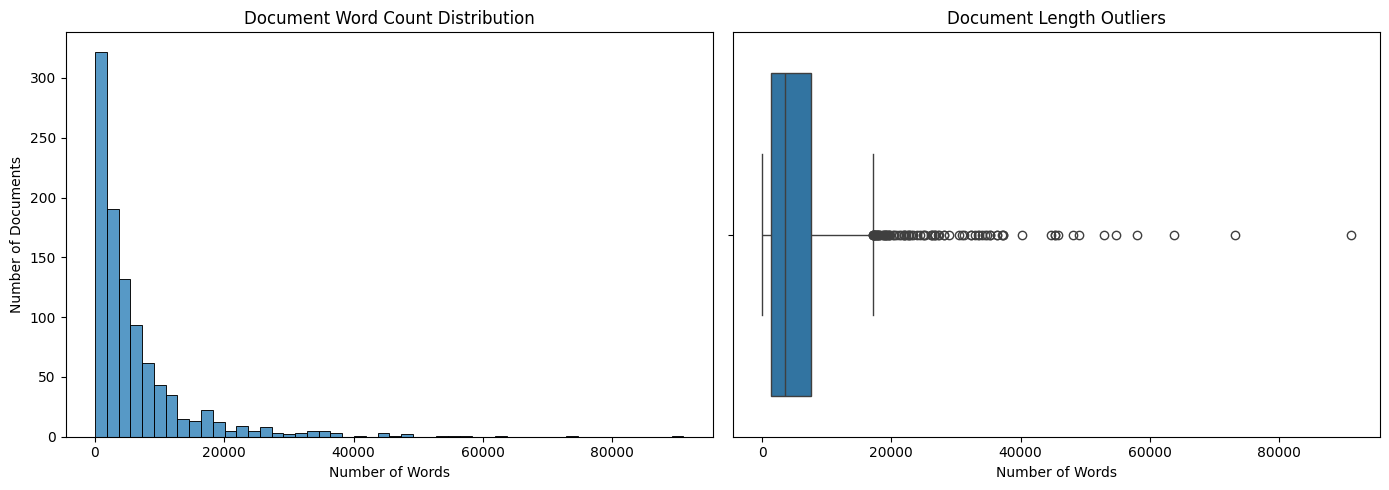

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(
    df["word_count"],
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Document Word Count Distribution")
axes[0].set_xlabel("Number of Words")
axes[0].set_ylabel("Number of Documents")
sns.boxplot(
    x=df["word_count"],
    ax=axes[1]
)
axes[1].set_title("Document Length Outliers")
axes[1].set_xlabel("Number of Words")
plt.tight_layout()
plt.show()


In [ ]:
Q1 = df["word_count"].quantile(0.25)
Q3 = df["word_count"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df["length_outlier"] = (
    (df["word_count"] < lower_bound) |
    (df["word_count"] > upper_bound)
)
print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Detected outliers:",
      df["length_outlier"].sum())
print("Outlier percentage:",
      round(df["length_outlier"].mean() * 100, 2), "%")
display(
    df.loc[df["length_outlier"],
           ["type", "citation", "word_count"]]
      .sort_values("word_count", ascending=False)
      .head(10)
)

Lower bound: -8134.75
Upper bound: 17119.25
Detected outliers: 89
Outlier percentage: 8.9 %


,type,citation,word_count
322,decision,Campbell v Northern Territory of Australia (No...,91018
424,primary_legislation,Petroleum and Geothermal Energy Resources Act ...,73219
966,decision,Wagonga Local Aboriginal Land Council v Attorn...,63637
791,primary_legislation,Retirement Villages Act 1999 (NSW),58037
122,decision,Australian Securities and Investments Commissi...,54797
249,secondary_legislation,Transport Operations (Road Use Management—Vehi...,52933
795,primary_legislation,Offshore Minerals Act 1999 (NSW),49013
88,primary_legislation,Offshore Minerals Act 1998 (Qld),48132
991,secondary_legislation,Kempsey Local Environmental Plan 2013 (2013-71...,45748
32,decision,Poniatowska v Hickinbotham [2009] FCA 680,45314



### Document Length Outlier Analysis

Document lengths were analyzed using word counts,
character counts, histograms, and boxplots.

The Interquartile Range (IQR) method was used
to identify unusually long or short documents.

**Handling Decision:**

Statistical outliers were retained because legal
documents naturally vary considerably in length.

Removing long documents could discard valuable
case law, legislation, or legal references.

The `length_outlier` column was added to flag
these documents for inspection.

Long documents will be divided into smaller
chunks during the RAG implementation phase.


##7. Final Validation and Dataset Export

In [ ]:
print("FINAL DATA QUALITY REPORT")
print("-" * 40)
print("Total documents:", len(df))
print("Total columns:", len(df.columns))
print("\nMissing values:")
display(df.isna().sum())
print("\nDuplicate IDs:",
      df["version_id"].duplicated().sum())
print("Duplicate URLs:",
      df["url"].duplicated().sum())
print("Duplicate texts:",
      df["text"].duplicated().sum())
print("\nEmpty legal documents:",
      df["text"].fillna("").str.strip().eq("").sum())
print("\nLength outliers:",
      df["length_outlier"].sum())
assert len(df) == 1000
assert df["version_id"].is_unique
assert df["url"].is_unique
assert df["text"].notna().all()
assert df["text"].str.strip().ne("").all()
assert df["date_missing"].equals(df["date"].isna())
print("\nAll final integrity checks passed!")

FINAL DATA QUALITY REPORT
----------------------------------------
Total documents: 1000
Total columns: 14

Missing values:


,0
version_id,0
type,0
jurisdiction,0
source,0
mime,0
date,107
citation,0
url,0
when_scraped,0
text,0



Duplicate IDs: 0
Duplicate URLs: 0
Duplicate texts: 0

Empty legal documents: 0

Length outliers: 89

All final integrity checks passed!


In [ ]:
from google.colab import files
df.to_csv(
    "australian_legal_corpus_cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)
files.download("australian_legal_corpus_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
preview = df.copy()
preview["text"] = (
    preview["text"]
    .fillna("")
    .str.replace(r"\s+", " ", regex=True)
    .str.slice(0, 200)
)
preview["when_scraped"] = (
    pd.to_datetime(preview["when_scraped"], utc=True)
    .dt.tz_localize(None)
)
preview.to_excel(
    "australian_legal_corpus_preview.xlsx",
    index=False
)
files.download("australian_legal_corpus_preview.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## 8. Final Cleaning Summary

The Australian Legal Corpus sample was cleaned and
validated for use in the LexiAssist project.

### Cleaning Performed
- Investigated and preserved missing publication dates
- Checked duplicate records and document identifiers
- Standardized metadata formats
- Normalized Unicode and unnecessary whitespace
- Preserved legal citations, punctuation, and structure
- Investigated document-length outliers
- Validated dataset integrity

### Final Dataset

The cleaned corpus contains 1,000 legal documents.

Missing publication dates and statistical length
outliers were retained to avoid losing useful
legal information.

The cleaned dataset was exported as
`australian_legal_corpus_cleaned.csv`.

### Next Stage

The cleaned corpus will be used for exploratory
data analysis to study legal document distributions,
jurisdiction coverage, publication trends, and
document-length characteristics.
